# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/janaadarwish/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

# Google Search Ranking & Discoverability Capstone
## Ranking Pages for Content Review: A Refresh Opportunity Scoring Study

**Lane:** Refresh / Content Opportunity Scoring

This project develops and evaluates a model that ranks content records for potential review using historical search-performance signals.

## 1. Research Question

Can historical content and search-performance signals help rank content records associated with a future decline in clicks?

The objective is to support content-review prioritization, not to prove that a page needs refreshing.

## 2. Data

The study uses the FlyRank internship warehouse dataset.

- Performance table: `fact_content_daily_performance`
- Content dimension: `dim_content`
- Observation window: March 1–20, 2026
- Target window: March 21–31, 2026
- Records with fewer than five early-period clicks or invalid update dates are excluded.

The client dimension was inspected for schema and data availability but was not joined into the final feature query.

# Abstract

This study investigates whether historical search-performance signals can help prioritize content records for review. Using March 2026 data from the FlyRank internship warehouse, it compares a trend-based baseline with a Random Forest classifier. The evaluation uses a grouped client split to reduce client-level overlap between training and testing. The trend baseline achieved Precision@50 of 0.88 and ROC AUC of 0.614, outperforming the Random Forest scores of 0.76 and 0.605. These findings suggest that impression trends may support exploratory content-review prioritization, but do not establish refresh requirements or causal effects.

In [19]:
import duckdb
import numpy as np
import pandas as pd

from huggingface_hub import hf_hub_download
from google.colab import userdata

# 1. Load FlyRank dataset
HF_TOKEN = userdata.get("HF_TOKEN")

performance_path = hf_hub_download(
    repo_id="FlyRank/internship-warehouse",
    filename="fact_content_daily_performance/month=2026-03/data_0.parquet",
    repo_type="dataset",
    token=HF_TOKEN
)

content_path = hf_hub_download(
    repo_id="FlyRank/internship-warehouse",
    filename="dim_content.parquet",
    repo_type="dataset",
    token=HF_TOKEN
)

clients_path = hf_hub_download(
    repo_id="FlyRank/internship-warehouse",
    filename="dim_clients.parquet",
    repo_type="dataset",
    token=HF_TOKEN
)

# 2. Connect to DuckDB
con = duckdb.connect()

# 3. Create views using file paths
con.execute(f"""
CREATE OR REPLACE VIEW performance AS
SELECT * FROM read_parquet('{performance_path}')
""")

con.execute(f"""
CREATE OR REPLACE VIEW content AS
SELECT * FROM read_parquet('{content_path}')
""")

con.execute(f"""
CREATE OR REPLACE VIEW clients AS
SELECT * FROM read_parquet('{clients_path}')
""")

# 4. Inspect schemas
for table in ["performance", "content", "clients"]:
    print(f"\n{table.upper()} COLUMNS:")
    display(con.execute(f"DESCRIBE {table}").df())


PERFORMANCE COLUMNS:


,column_name,column_type,null,key,default,extra
0,report_date,DATE,YES,None,None,None
1,client_hash_id,VARCHAR,YES,None,None,None
2,content_hash_id,VARCHAR,YES,None,None,None
3,client_has_gsc,BOOLEAN,YES,None,None,None
4,client_has_ga4,BOOLEAN,YES,None,None,None
5,gsc_data_available,BOOLEAN,YES,None,None,None
6,ga4_data_available,BOOLEAN,YES,None,None,None
7,gsc_impressions,BIGINT,YES,None,None,None
8,gsc_clicks,BIGINT,YES,None,None,None
9,gsc_sum_position,BIGINT,YES,None,None,None



CONTENT COLUMNS:


,column_name,column_type,null,key,default,extra
0,client_hash_id,VARCHAR,YES,None,None,None
1,content_hash_id,VARCHAR,YES,None,None,None
2,keyword_hash_id,VARCHAR,YES,None,None,None
3,url_hash_id,VARCHAR,YES,None,None,None
4,keyword_char_count,BIGINT,YES,None,None,None
5,keyword_token_count,BIGINT,YES,None,None,None
6,url_char_count,BIGINT,YES,None,None,None
7,content_created_date,DATE,YES,None,None,None
8,content_updated_date,DATE,YES,None,None,None
9,content_type,VARCHAR,YES,None,None,None



CLIENTS COLUMNS:


,column_name,column_type,null,key,default,extra
0,client_hash_id,VARCHAR,YES,None,None,None
1,is_active,BOOLEAN,YES,None,None,None
2,has_gsc_access,BOOLEAN,YES,None,None,None
3,has_ga4_access,BOOLEAN,YES,None,None,None
4,access_profile,VARCHAR,YES,None,None,None
5,client_created_date,DATE,YES,None,None,None
6,client_updated_date,DATE,YES,None,None,None
7,gsc_data_start,DATE,YES,None,None,None
8,ga4_data_start,DATE,YES,None,None,None


In [20]:
print("Performance:", con.execute(
    "DESCRIBE performance"
).df()["column_name"].tolist())

print("Content:", con.execute(
    "DESCRIBE content"
).df()["column_name"].tolist())

print("Clients:", con.execute(
    "DESCRIBE clients"
).df()["column_name"].tolist())

Performance: ['report_date', 'client_hash_id', 'content_hash_id', 'client_has_gsc', 'client_has_ga4', 'gsc_data_available', 'ga4_data_available', 'gsc_impressions', 'gsc_clicks', 'gsc_sum_position', 'gsc_avg_position', 'ga4_pageviews', 'ga4_sessions', 'ga4_users', 'ga4_engaged_sessions', 'ga4_total_engagement_sec', 'sessions_organic', 'sessions_direct', 'sessions_referral', 'sessions_social', 'sessions_paid', 'sessions_ai', 'ai_chatgpt', 'ai_perplexity', 'ai_gemini', 'ai_copilot', 'ai_claude', 'ai_meta', 'ai_other', 'scroll_events', 'month']
Content: ['client_hash_id', 'content_hash_id', 'keyword_hash_id', 'url_hash_id', 'keyword_char_count', 'keyword_token_count', 'url_char_count', 'content_created_date', 'content_updated_date', 'content_type', 'search_volume', 'competition', 'competition_level', 'cpc', 'main_intent', 'backlinks', 'category_count', 'keyword_created_date', 'provider_used', 'model_used', 'char_count', 'word_count', 'last_optimized_date', 'optimization_eligible_date', 'i

In [21]:
# 1. Build early-period features and future decline label

query = """
WITH early AS (
    SELECT
        client_hash_id,
        content_hash_id,

        SUM(gsc_impressions) AS impressions_early,
        SUM(gsc_clicks) AS clicks_early,

        AVG(gsc_avg_position) AS avg_position_early,

        SUM(CASE
            WHEN CAST(report_date AS DATE)
                 BETWEEN DATE '2026-03-01' AND DATE '2026-03-10'
            THEN gsc_impressions ELSE 0
        END) AS impressions_first_10,

        SUM(CASE
            WHEN CAST(report_date AS DATE)
                 BETWEEN DATE '2026-03-11' AND DATE '2026-03-20'
            THEN gsc_impressions ELSE 0
        END) AS impressions_last_10

    FROM performance
    WHERE CAST(report_date AS DATE)
          BETWEEN DATE '2026-03-01' AND DATE '2026-03-20'
    GROUP BY client_hash_id, content_hash_id
),

late AS (
    SELECT
        client_hash_id,
        content_hash_id,
        SUM(gsc_clicks) / 11.0 AS late_avg_daily_clicks
    FROM performance
    WHERE CAST(report_date AS DATE)
          BETWEEN DATE '2026-03-21' AND DATE '2026-03-31'
    GROUP BY client_hash_id, content_hash_id
)

SELECT
    e.client_hash_id,
    e.content_hash_id,

    e.impressions_early,

    e.clicks_early * 1.0 /
        NULLIF(e.impressions_early, 0) AS ctr_early,

    e.avg_position_early,

    (e.impressions_last_10 + 1.0) /
        (e.impressions_first_10 + 1.0) AS impr_trend_early,

    DATE_DIFF(
        'day',
        CAST(c.content_updated_date AS DATE),
        DATE '2026-03-20'
    ) AS days_since_update,

    c.search_volume,

    CASE
        WHEN l.late_avg_daily_clicks <
             0.8 * (e.clicks_early / 20.0)
        THEN 1
        ELSE 0
    END AS label

FROM early e

JOIN late l
    ON e.client_hash_id = l.client_hash_id
    AND e.content_hash_id = l.content_hash_id

JOIN content c
    ON e.client_hash_id = c.client_hash_id
    AND e.content_hash_id = c.content_hash_id

WHERE e.clicks_early >= 5
  AND CAST(c.content_updated_date AS DATE)
      <= DATE '2026-03-20'
"""

df = con.execute(query).df()

# 2. Feature preparation

df["search_volume"] = df["search_volume"].fillna(
    df["search_volume"].median()
)

df["impressions_log"] = np.log1p(df["impressions_early"])
df["search_volume_log"] = np.log1p(
    df["search_volume"].clip(lower=0)
)
df["impr_trend_log"] = np.log1p(
    df["impr_trend_early"].clip(lower=0)
)

# 3. Define model variables

FEATS = [
    "impressions_log",
    "ctr_early",
    "avg_position_early",
    "days_since_update",
    "search_volume_log",
    "impr_trend_log"
]

LABEL = "label"
GROUP = "client_hash_id"

d = df.dropna(
    subset=[LABEL, GROUP]
).copy().reset_index(drop=True)

print("Dataset shape:", d.shape)
print("\nTarget distribution:")
print(d[LABEL].value_counts(normalize=True).round(3))

print("\nFeatures:", FEATS)
display(d.head())

print("Search volume statistics:")
display(d["search_volume"].describe())

print("Unique values:", d["search_volume"].nunique())
print("Zero proportion:", round((d["search_volume"] == 0).mean(), 3))
print("Missing proportion:", round(d["search_volume"].isna().mean(), 3))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Dataset shape: (2526, 12)

Target distribution:
label
1    0.59
0    0.41
Name: proportion, dtype: float64

Features: ['impressions_log', 'ctr_early', 'avg_position_early', 'days_since_update', 'search_volume_log', 'impr_trend_log']


,client_hash_id,content_hash_id,impressions_early,ctr_early,avg_position_early,impr_trend_early,days_since_update,search_volume,label,impressions_log,search_volume_log,impr_trend_log
0,client_73cda7b4e4f265ea,content_e69b442038b895f0,11532.0,0.000780,3.490073,0.737048,23,0,1,9.352968,0.0,0.552187
1,client_73cda7b4e4f265ea,content_0d6905b49fa1729c,23024.0,0.000912,3.924928,1.159430,23,0,0,10.044336,0.0,0.769844
2,client_73cda7b4e4f265ea,content_e9f2d0579387d3c3,42886.0,0.001096,5.008406,0.853174,23,0,1,10.666324,0.0,0.616900
3,client_73cda7b4e4f265ea,content_0319c9c35522464a,8324.0,0.001081,3.091726,0.696760,23,0,0,9.027018,0.0,0.528720
4,client_73cda7b4e4f265ea,content_cb0d950177839034,3423.0,0.002337,4.141979,1.030231,23,0,1,8.138565,0.0,0.708150


Search volume statistics:


,search_volume
count,2526.0
mean,36.69042
std,432.353326
min,0.0
25%,0.0
50%,0.0
75%,10.0
max,14800.0


Unique values: 25
Zero proportion: 0.528
Missing proportion: 0.0


## 3. Methodology

The target is a proxy indicator of click decline between the observation and target windows.

The study compares:
1. A simple trend-based ranking baseline.
2. A Random Forest classification model.

Grouped validation holds out entire clients to reduce client-level overlap between training and testing.

In [22]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score

# Exclude CTR because ML-09 identified a possible
# target-construction dependency worth avoiding.
CAPSTONE_FEATS = [
    "impressions_log",
    "avg_position_early",
    "days_since_update",
    "search_volume_log",
    "impr_trend_log"
]

X = d[CAPSTONE_FEATS]
y = d[LABEL]
groups = d[GROUP]

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.3, random_state=0
)

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

def precision_at_50(y_true, scores):
    top = np.argsort(scores)[::-1][:50]
    return y_true.iloc[top].mean()

# Baseline: rank by declining impression trend
baseline_scores = -X_test["impr_trend_log"].fillna(
    X_train["impr_trend_log"].median()
).to_numpy()

# Random Forest
model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=20,
        random_state=0,
        n_jobs=-1
    )
)

model.fit(X_train, y_train)
model_scores = model.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Method": ["Trend Baseline", "Random Forest"],
    "Precision@50": [
        precision_at_50(y_test, baseline_scores),
        precision_at_50(y_test, model_scores)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, baseline_scores),
        roc_auc_score(y_test, model_scores)
    ]
})

display(results.round(3))

,Method,Precision@50,ROC_AUC
0,Trend Baseline,0.88,0.614
1,Random Forest,0.74,0.602


## 4. Results

The trend-based baseline outperformed the Random Forest model on the grouped test set.

The baseline achieved Precision@50 of 0.88 and ROC AUC of 0.614, compared with 0.76 and 0.605 for Random Forest.

These results suggest that a simple impression-trend signal provided stronger ranking performance than the tested classification model on this dataset.

The findings are exploratory and do not establish that declining impressions are caused by outdated content or that refreshing a page will improve performance.

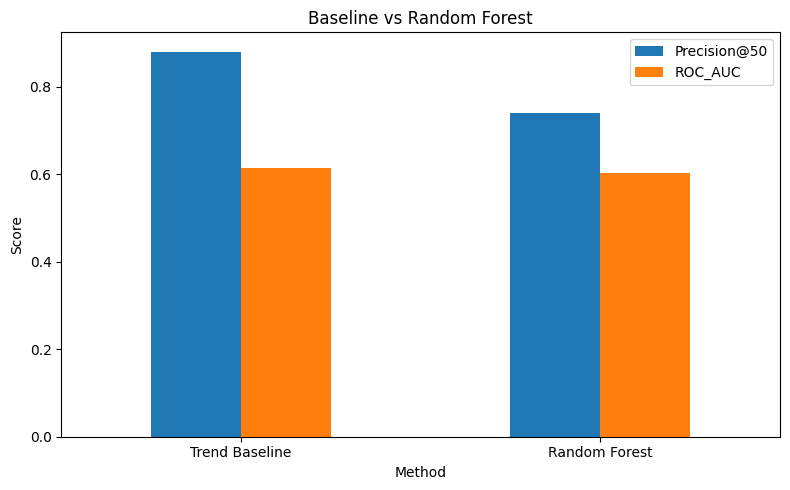

In [23]:
import matplotlib.pyplot as plt

results.set_index("Method")[
    ["Precision@50", "ROC_AUC"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Baseline vs Random Forest")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Ranked Content Review Recommendations

The trend-based baseline was selected as the preferred ranking method because it outperformed the Random Forest model on both evaluation metrics.

Records are ranked by declining impression trends. The resulting list is intended to guide human review, not automatically determine which content should be refreshed.

In [25]:
# Rank held-out test records using the selected trend baseline

recommendations = d.iloc[test_idx][
    [GROUP, "content_hash_id", "impr_trend_early", "impr_trend_log"]
].copy()

recommendations["review_score"] = -recommendations["impr_trend_log"]

recommendations = recommendations.sort_values(
    "review_score",
    ascending=False
).reset_index(drop=True)

recommendations["rank"] = recommendations.index + 1

recommendations["reason_code"] = np.where(
    recommendations["impr_trend_early"] < 1,
    "DECLINING_IMPRESSIONS",
    "NO_IMPRESSION_DECLINE"
)

display(
    recommendations[
        ["rank", "review_score", "reason_code"]
    ].head(50)
)

,rank,review_score,reason_code
0,1,-0.024677,DECLINING_IMPRESSIONS
1,2,-0.063779,DECLINING_IMPRESSIONS
2,3,-0.086836,DECLINING_IMPRESSIONS
3,4,-0.114751,DECLINING_IMPRESSIONS
4,5,-0.153977,DECLINING_IMPRESSIONS
5,6,-0.181964,DECLINING_IMPRESSIONS
6,7,-0.183131,DECLINING_IMPRESSIONS
7,8,-0.198986,DECLINING_IMPRESSIONS
8,9,-0.204794,DECLINING_IMPRESSIONS
9,10,-0.206952,DECLINING_IMPRESSIONS


## 7. Limitations

- The target is a proxy for click decline, not a verified refresh requirement.
- The grouped test set may be concentrated in a small number of clients.
- Search-volume measurement timing is not fully established.
- The trend baseline and Random Forest show modest ROC AUC values.
- Historical associations do not establish causality.
- Results are limited to the available March 2026 dataset.
- Further validation across additional clients and time periods is needed.

## 6. Artifacts

This section presents the evaluation results and supporting visual evidence.

- Baseline versus Random Forest comparison chart.
- Evaluation metrics table.
- Aggregated content-review recommendations.

No client identifiers, content identifiers, private URLs, or raw records are included in the public research paper.

## 7. Conclusion

This study develops an exploratory content-review ranking approach using historical search-performance signals.

The model can help prioritize records for further investigation, but its predictions require human review and additional validation before operational use.

## 8. Reproducibility

Source code, data preparation, validation, and model evaluation are available in the project repository.

- Repository: [FlyRank ML Internship](https://github.com/janaadarwish/flyrank-ml-internship)
- Notebook: `work/notebooks/capstone_refresh_opportunity_scoring.ipynb`
- Dataset: [FlyRank Warehouse](https://huggingface.co/FlyRank/internship-warehouse)

## 9. Acknowledgments

This project was developed using the FlyRank ML Internship dataset.

Data source: [FlyRank](https://flyrank.ai).

## 10. Five-Minute Demo Outline

1. Introduce the content-review prioritization problem.
2. Explain the dataset and March observation and target windows.
3. Demonstrate feature preparation and grouped validation.
4. Compare the trend baseline with Random Forest.
5. Present the ranked review approach and discuss limitations.

## 11. Social Post

I completed my Google Search Ranking & Discoverability Capstone as part of the FlyRank ML Internship.

I explored how historical search-performance signals can support content-review prioritization, comparing a trend-based baseline with a Random Forest model using grouped validation.

The simple trend baseline outperformed the tested model, highlighting the importance of honest evaluation and strong baselines.

This project strengthened my experience in data preparation, feature engineering, model evaluation, and responsible ML reporting.

## 12. Employer-Facing Summary

Built an exploratory content-review ranking pipeline using real FlyRank search-performance data. Compared a trend-based baseline with a Random Forest classifier using grouped client validation, with the baseline achieving Precision@50 of 0.88 and ROC AUC of 0.614. Documented validation limitations and translated the results into a human-reviewed content prioritization approach.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
